In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as spo
import numpy.polynomial.chebyshev as cheb
from scipy.special import chebyt

In [2]:
def machnumber(x):
    if np.abs(x)>1:
        M = 1
    else:
        f = lambda M: 2*np.arctan(M)-M-(0.5*np.pi-1)*np.abs(x)
        M = spo.root_scalar(f,bracket=[0,1]).root
    if x<0:
        return -M
    return M

def M(X):
    res = np.zeros(X.size)
    for i in range(X.size):
        res[i]=machnumber(X[i])
    return res

def density(M):
    return 1/(1+M**2)


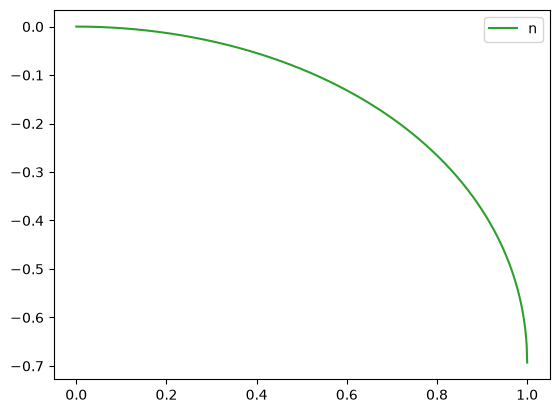

In [64]:
plt.figure()
X = np.linspace(0,1,1000)

plt.plot(X, np.log(density(M(X))),'C2',label = 'n')

plt.legend()

0.4999999999999998
1.0000000000000009


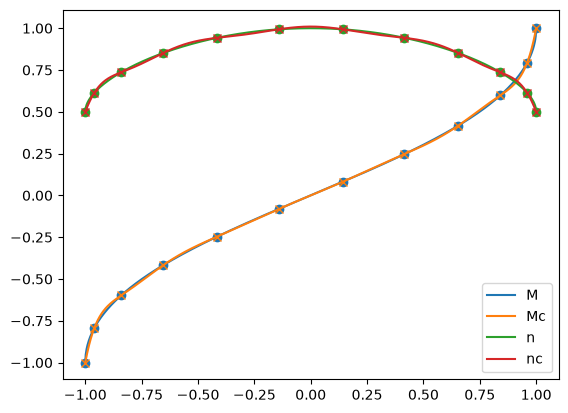

In [18]:
N = 12
extrema = True

plt.figure()
X = np.linspace(-1,1,1000)

if extrema:
    Xc = cheb.chebpts2(N)
    Mcoeff=cheb.chebfit(Xc,M(Xc),N-1)
    eta = np.log(density(M(Xc)))
    etacoeff=cheb.chebfit(Xc,eta,N-1)
else:
    Xc = cheb.chebpts1(N)
    Mcoeff = cheb.chebinterpolate(M,N)
    etacoeff = cheb.chebinterpolate(lambda x: np.log(density(M(x))),N)

    

Mc = cheb.Chebyshev(Mcoeff)
nc = lambda x: np.exp(cheb.Chebyshev(etacoeff)(x))

plt.plot(X, M(X),'C0',label = 'M')
plt.plot(Xc,M(Xc),'C0o')

plt.plot(X, Mc(X),'C1',label = 'Mc')
plt.plot(Xc,Mc(Xc),'C1x')

plt.plot(X, density(M(X)),'C2',label = 'n')
plt.plot(Xc,density(M(Xc)),'C2o')

plt.plot(X, nc(X),'C3',label = 'nc')
plt.plot(Xc,nc(Xc),'C3x')

plt.legend()

print(nc(1))

print(Mc(1))

In [38]:
def density_eq(M,eta,alpha,n):
    # Chebyshev coefficients of the density equation at order n.
    N = M.size
    karr = np.arange(N)

    f1 = np.sum(((2*karr+1)*M)[n:])

    f2 = 0
    for m in range(N):
        for k in range(n+m+1,N):
            f2+= 2*k*eta[k]*M[m]

    f3 = 0
    for m in range(n):
        for k in range(n-m,min(N,n+m+1)):
            #print(f'm:{m},k:{k}')
            f3 += k*eta[k]*M[m]
    for m in range(n,N):
        for k in range(m-n+1,min(N,n+m+1)):
            min(N,n+m+1)
            f3 += k*eta[k]*M[m]

    f4 = 0
    if n==0:
        f4 = -alpha

    return f1+f2+f3+f4

def mach_eq(M,eta,alpha,n):
    # Chebyshev coefficients of the mach number equation at order n.
    N = M.size
    karr = np.arange(N)

    f1 = 0
    for m in range(N):
        for k in range(n+m+1,N):
            #print(f'f1, n: {n}, m:{m}, k:{k}')
            f1+= 2*(2*k+1)*M[k]*M[m]

    f2 = 0
    for m in range(N):
        for k in range(np.abs(n-m),min(N,n+m+1)):
            #print(f'f2, n: {n}, m:{m}, k:{k}')
            f2 += (2*k+1)*M[k]*M[m]

    f3 = alpha*M[n]
    
    f4 = np.sum((4*karr*eta)[n+1:])

    return f1+f2+f3+f4

def system(M,eta,alpha=0.5*np.pi-1):
    # Compute the residuals of the system of equations. M and eta are the 
    # Chebyshev coefficients of the mach number and log(density/density(0)) respectively.
    N = M.size
    karr = np.arange(N)

    res = [np.sum(M)-1,
           np.sum(eta*(-1)**karr)
          ]
    for n in range(N-1):
        res.append(density_eq(M,eta,alpha,n))
        res.append(mach_eq(M,eta,alpha,n))       

    return np.array(res)

In [39]:
def get_errors(N,extrema=False):

    if extrema:
        Xc = cheb.chebpts2(N)
        Mcoeff=cheb.chebfit(Xc,M(Xc),N-1)
        eta = np.log(density(M(Xc)))
        etacoeff=cheb.chebfit(Xc,eta,N-1)
    else:
        Xc = cheb.chebpts1(N)
        Mcoeff = cheb.chebinterpolate(M,N)
        etacoeff = cheb.chebinterpolate(lambda x: np.log(density(M(x))),N)

    return system(Mcoeff[1::2],etacoeff[::2])

In [40]:
for n in [3,5,7,9,11,13]:
    get_errors(n)

In [53]:
Narr = np.array([4,8,16,32,64,128,256])

ErrExt = np.zeros([4,Narr.size])
ErrRoot = np.zeros([4,Narr.size])

for i,n in enumerate(Narr):
    ErrExt[:,i] = get_errors(n,extrema=True)[:4]
    ErrRoot[:,i] = get_errors(n-1,extrema=False)[:4]

In [54]:
print(ErrRoot)

[[-1.84393652e-01 -9.38504243e-02 -4.71448430e-02 -2.36003526e-02
  -1.18036833e-02 -5.90228054e-03 -2.95119514e-03]
 [ 2.59937225e-02  3.50173216e-03  4.50184754e-04  5.67294801e-05
   7.10611745e-06  8.88736993e-07  1.11106930e-07]
 [-1.09966344e-02 -1.95168987e-02 -1.36518273e-02 -7.85379899e-03
  -4.19080716e-03 -2.16224902e-03 -1.09794444e-03]
 [ 2.65019177e-01  1.02719123e-01  4.36368700e-02  1.98427752e-02
   9.42186092e-03  4.58536291e-03  2.26120505e-03]]


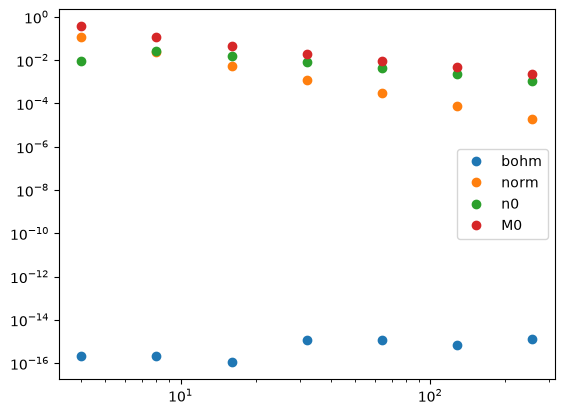

In [61]:
plt.figure()
for i, lab in zip(range(4), ['bohm', 'norm', 'n0', 'M0']):
    plt.loglog(Narr, np.abs(ErrExt[i,:]), f'C{i}o', label = lab)
    #plt.loglog(Narr, np.abs(ErrRoot[i,:]), f'C{i}x', label = lab)
plt.legend()

In [42]:
system(np.array([0.78,0.22,0]),np.array([-0.56,-0.56,0]))

array([ 0.        ,  0.        , -0.00439633, -0.01157887,  0.1       ,
        0.95717519])

In [6]:
Mcoeff = np.array([0.78,0.22])
etacoeff=np.array([-0.56,-0.56])

In [7]:
Mcoeff[0]**2+3*Mcoeff[1]**2+6*Mcoeff[1]*Mcoeff[0]+(0.5*np.pi-1)*Mcoeff[0]+4*etacoeff[1]

np.float64(-0.011578865099980629)